<a href="https://colab.research.google.com/github/Amyerm/ClassFiles/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

import statsmodels.api as sm
import statsmodels.formula.api as smf

df = pd.read_csv("college.csv")

datos = df[["salary", "cost", "location"]].copy()

datos.head()

,salary,cost,location
0,119000,189300,NE
1,121000,189600,NE
2,123000,188400,NE
3,123000,188700,NE
4,110000,194200,NE


In [15]:
datos["location"] = datos["location"].astype("category")

datos[["salary", "cost"]].describe()

,salary,cost
count,85.000000,85.000000
mean,95898.823529,142434.470588
std,11937.121912,53913.064578
min,74900.000000,18260.000000
25%,87100.000000,84670.000000
50%,93200.000000,169200.000000
75%,105000.000000,188700.000000
max,123000.000000,227300.000000


In [16]:
datos["location"].value_counts()

,count
location,
NE,25
W,21
S,20
MW,19


In [17]:
location_dummy = pd.get_dummies(
    datos["location"],
    prefix="location",
    drop_first=True,
    dtype=int
)

location_dummy.head()

,location_NE,location_S,location_W
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




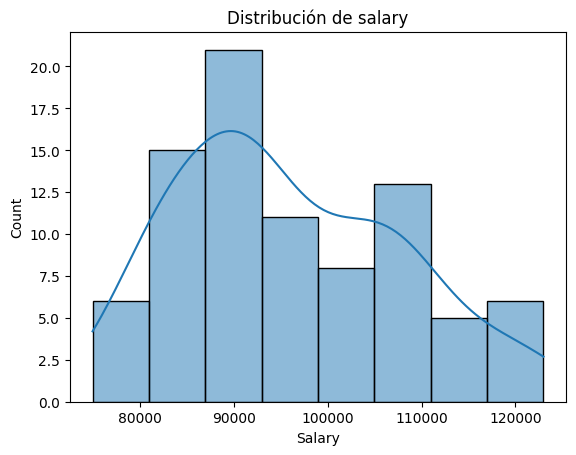

In [18]:
sns.histplot(datos["salary"], kde=True)
plt.title("Distribución de salary")
plt.xlabel("Salary")
plt.show()

La mayoría de los salarios se concentra aproximadamente entre 85,000 y 100,000. También se observan varios valores alrededor de 105,000 y 110,000, mientras que los salarios más altos aparecen con menor frecuencia. La distribución no es completamente simétrica, pero no se observan valores extremadamente alejados del resto.

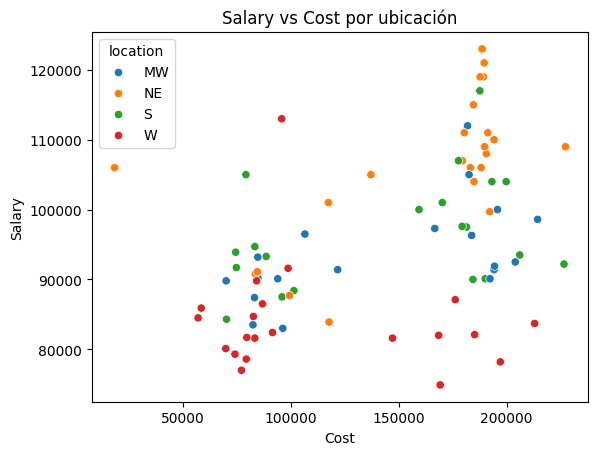

In [19]:
sns.scatterplot(
    data=datos,
    x="cost",
    y="salary",
    hue="location"
)

plt.title("Salary vs Cost por ubicación")
plt.xlabel("Cost")
plt.ylabel("Salary")
plt.show()

Se observa una relación positiva entre Cost y Salary, ya que los salarios tienden a aumentar conforme aumenta el costo y la relación cambia según la ubicación. En NE aparecen varios de los salarios más altos, mientras que en W se observan algunos costos elevados con salarios más bajos. Esto indica que la ubicación también puede influir en la relación entre el costo y el salario.

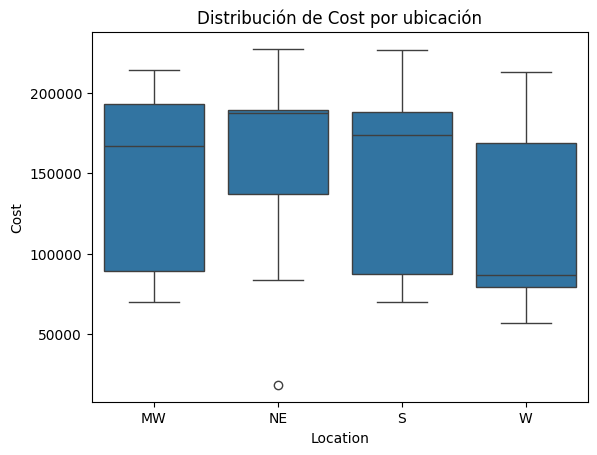

In [20]:
sns.boxplot(
    data=datos,
    x="location",
    y="cost"
)

plt.title("Distribución de Cost por ubicación")
plt.xlabel("Location")
plt.ylabel("Cost")
plt.show()

Se observan diferencias en los costos según la ubicación. NE y S presentan costos generalmente más altos, mientras que W muestra una mediana de costo menor. MW se encuentra en un nivel intermedio. También se observa un valor atípico bajo en NE, por lo que la distribución del costo no es igual en todas las localidades.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [21]:
# Construcción del modelo de regresión

X = pd.concat(
    [datos[["cost"]], location_dummy],
    axis=1
)

y = datos["salary"]

modelo = LinearRegression()
modelo.fit(X, y)

print("Intercepto:", modelo.intercept_)

coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo.coef_
})

coeficientes

Intercepto: 84988.71622754404


,Variable,Coeficiente
0,cost,0.060518
1,location_NE,12032.819692
2,location_S,2800.345026
3,location_W,-7721.420103


El intercepto representa el salario estimado para una universidad ubicada en MW cuando el costo es igual a cero, con un valor aproximado de 84,989.

El coeficiente de Cost es aproximadamente 0.0605, lo que indica que, manteniendo fija la ubicación, por cada unidad adicional de costo el salario estimado aumenta alrededor de 0.06 unidades.

La categoría NE tiene un coeficiente positivo de aproximadamente 12,033, por lo que, manteniendo constante el costo, una universidad ubicada en NE tiene un salario estimado alrededor de 12,033 unidades mayor que una ubicada en MW.

Para S, el salario estimado es aproximadamente 2,800 unidades mayor que en MW, manteniendo constante el costo. En cambio, W tiene un coeficiente negativo de aproximadamente -7,721, lo que indica que su salario estimado es alrededor de 7,721 unidades menor que en MW, considerando el mismo costo.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

In [22]:
# Predicciones y residuos

y_pred = modelo.predict(X)
residuos = y - y_pred

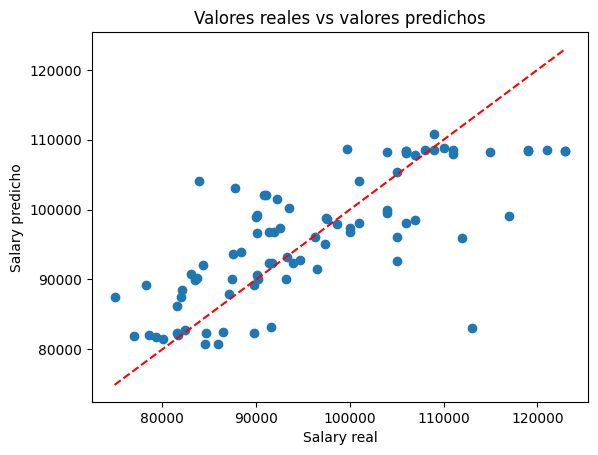

In [23]:
plt.scatter(y, y_pred)

plt.xlabel("Salary real")
plt.ylabel("Salary predicho")
plt.title("Valores reales vs valores predichos")

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color="red",
    linestyle="--"
)

plt.show()

Los valores predichos siguen una tendencia similar a los valores reales, ya que muchos puntos se encuentran cerca de la línea diagonal. También se observan varios puntos alejados de la línea, lo que indica que existen errores de predicción en algunos casos. El ajuste visual es aceptable, aunque no es perfecto.

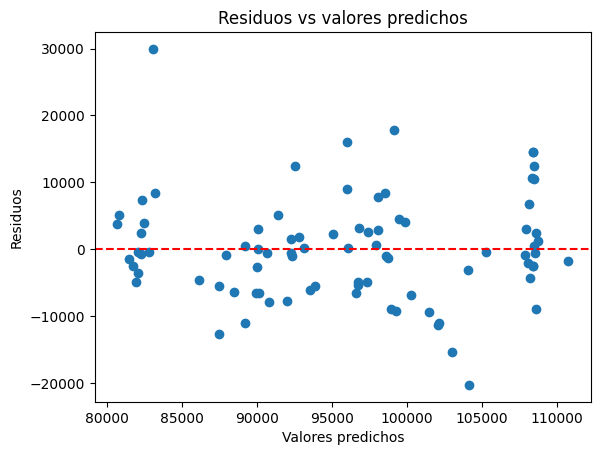

In [24]:
plt.scatter(y_pred, residuos)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos vs valores predichos")

plt.show()

Los residuos se encuentran distribuidos alrededor de la línea de cero, aunque no de manera completamente uniforme. Se observan algunos valores alejados, tanto positivos como negativos, lo que indica que existen casos con errores de predicción más altos. No se aprecia un patrón totalmente definido, pero la dispersión muestra que el modelo no ajusta igual de bien todas las observaciones.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [25]:
# Evaluación del modelo

mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("MSE:", mse)
print("R²:", r2)

MSE: 60480269.14657189
R²: 0.5705089716684086


El modelo obtuvo un R² aproximado de 0.57, lo que indica que cerca del 57.1% de la variación de los salarios puede ser explicada por el costo y la ubicación. Esto representa un ajuste moderado, ya que todavía existe una parte importante de la variación que el modelo no logra explicar. El MSE fue de aproximadamente 60.5 millones, lo que refleja la magnitud de los errores al estar expresado en unidades al cuadrado.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [26]:
# Análisis de varianza

modelo_anova = smf.ols(
    "salary ~ cost + C(location)",
    data=datos
).fit()

anova = sm.stats.anova_lm(modelo_anova, typ=2)

anova

,sum_sq,df,F,PR(>F)
C(location),4.071774e+09,3.0,21.121259,3.570975e-10
cost,7.878166e+08,1.0,12.259774,7.600629e-04
Residual,5.140823e+09,80.0,NaN,NaN


En el análisis de varianza se observa que tanto Location como Cost presentan p-values menores a 0.05. Esto indica que ambas variables tienen un efecto estadísticamente significativo sobre Salary. La ubicación presenta una evidencia especialmente fuerte de diferencias entre localidades, mientras que el costo también tiene una relación significativa con el salario.